In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                              roc_curve, roc_auc_score)
import shap
import joblib

In [3]:
# Load dataset
df = pd.read_csv('Telco_Customer_Churn.csv')

# Basic info
print(df.info())
print(df.describe())
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
df.drop('customerID', axis=1, inplace=True)

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.dropna(inplace=True)

df.reset_index(drop=True, inplace=True)

**VISUALIZATION**

C:\Users\himan\AppData\Local\Temp\ipykernel_28124\200257233.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Churn', palette='Set2')


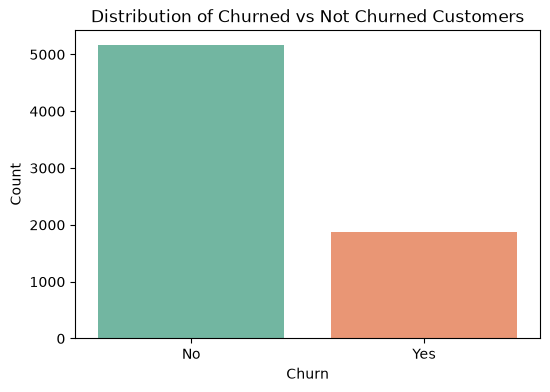

In [5]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Churn', palette='Set2')
plt.title('Distribution of Churned vs Not Churned Customers')
plt.xlabel('Churn')
plt.ylabel('Count')
plt.show()

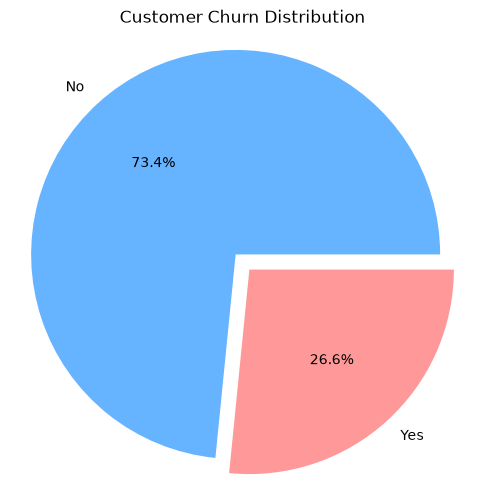

In [6]:
churn_counts = df['Churn'].value_counts()
labels = churn_counts.index
sizes = churn_counts.values
colors = ['#66b3ff','#ff9999']

plt.figure(figsize=(6, 6))
plt.pie(sizes, labels=labels, autopct='%1.1f%%', colors=colors, explode=(0, 0.1))
plt.title('Customer Churn Distribution')
plt.axis('equal')
plt.show()

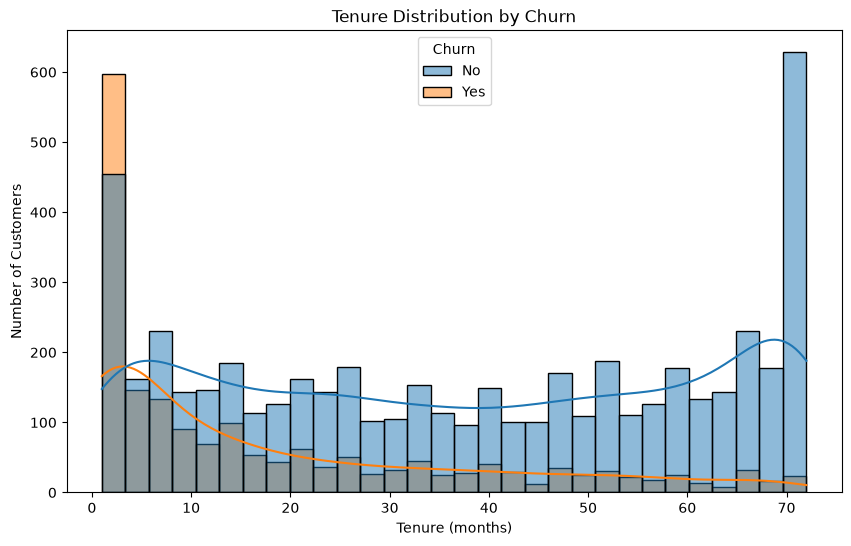

In [7]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='tenure', hue='Churn', bins=30, kde=True)
plt.title('Tenure Distribution by Churn')
plt.xlabel('Tenure (months)')
plt.ylabel('Number of Customers')
plt.show()

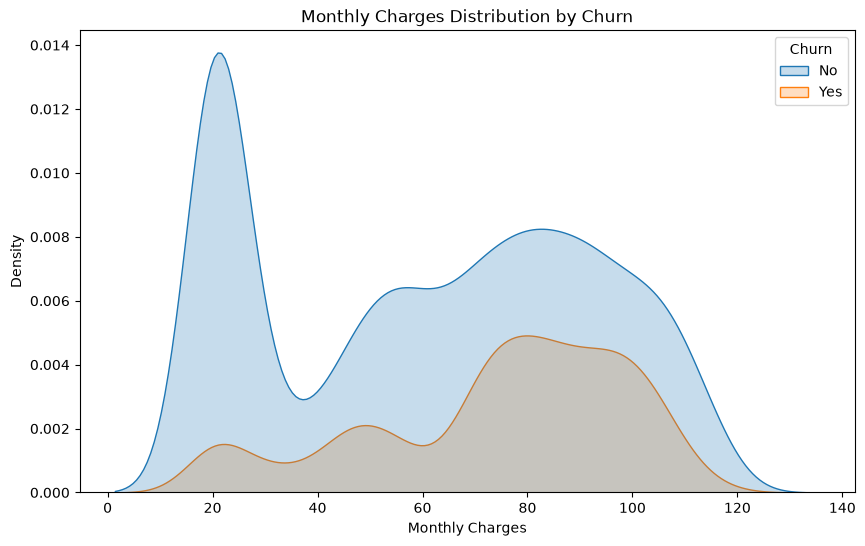

In [8]:
plt.figure(figsize=(10, 6))
sns.kdeplot(data=df, x="MonthlyCharges", hue="Churn", fill=True)
plt.title("Monthly Charges Distribution by Churn")
plt.xlabel("Monthly Charges")
plt.ylabel("Density")
plt.show()

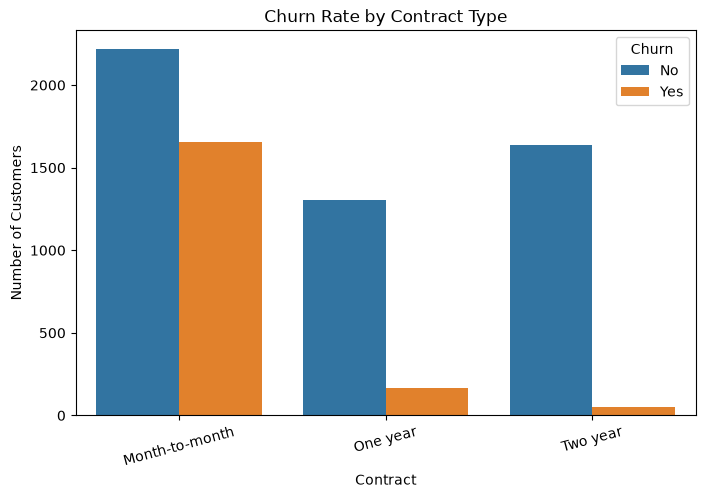

In [9]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Churn Rate by Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.show()

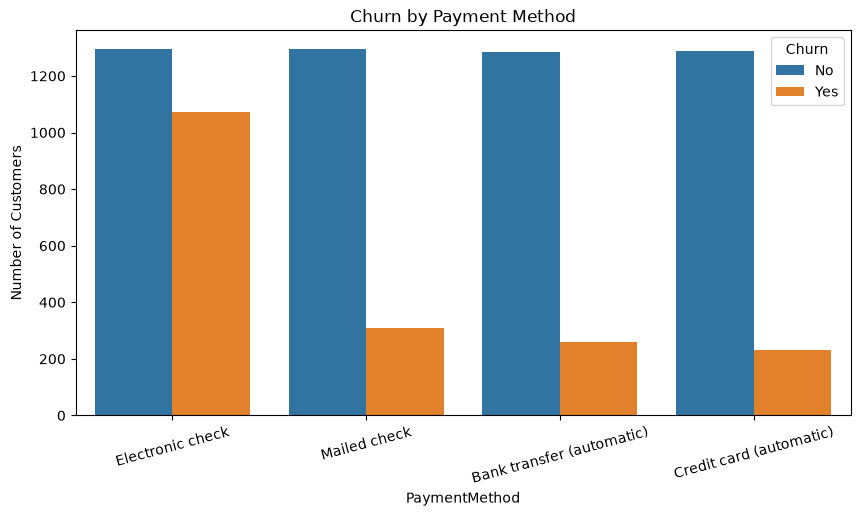

In [10]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="PaymentMethod", hue="Churn")
plt.title("Churn by Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.show()

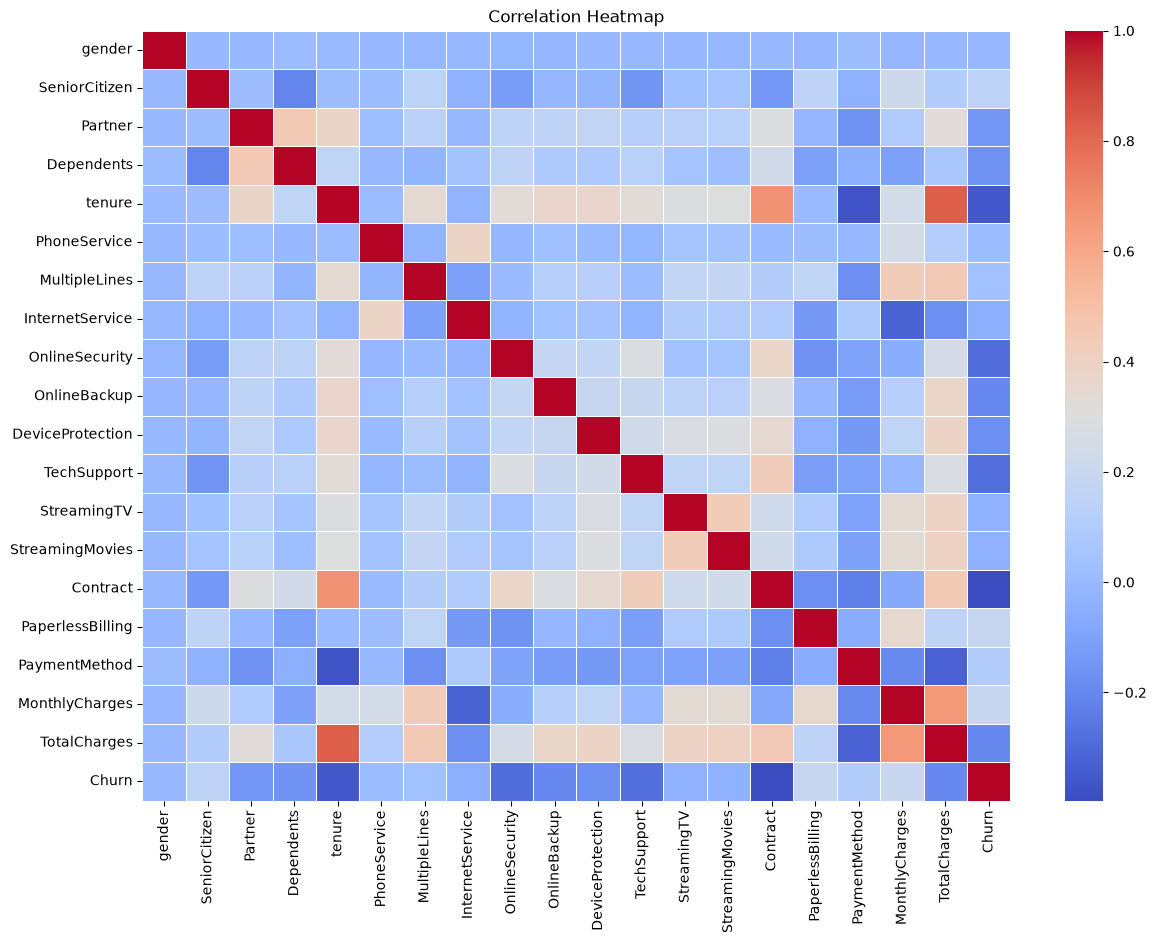

In [11]:
df_encoded = df.copy()
le = LabelEncoder()
for col in df_encoded.columns:
    if df_encoded[col].dtype == 'object' or pd.api.types.is_string_dtype(df_encoded[col]):
        df_encoded[col] = le.fit_transform(df_encoded[col])

plt.figure(figsize=(14,10))
corr = df_encoded.corr()
sns.heatmap(corr, annot=False, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

### Preprocessing

Churn is imbalanced (~73% No / ~27% Yes) and most features are nominal categories (payment method, internet
service, contract type, etc.), so the pipeline below one-hot encodes categoricals and scales numeric columns
inside a single `Pipeline`, fit only on the training fold to avoid leakage.

In [12]:
X = df.drop('Churn', axis=1)
y = df['Churn'].map({'Yes': 1, 'No': 0})

categorical_cols = X.select_dtypes(include='object').columns.tolist()
numeric_cols = X.select_dtypes(exclude='object').columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numeric_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), categorical_cols)
])

C:\Users\himan\AppData\Local\Temp\ipykernel_28124\2710041913.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include='object').columns.tolist()


### Model comparison

Since churn is imbalanced, accuracy alone would be misleading (predicting "No churn" for everyone already
scores ~73%). Each model below uses `class_weight` / `scale_pos_weight` to account for that, and is compared
with 5-fold stratified cross-validation across Accuracy, Precision, Recall, F1, and ROC-AUC.

In [13]:
candidate_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(class_weight='balanced', random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(),
    'XGBoost': XGBClassifier(
        eval_metric='logloss', random_state=42,
        scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum()
    )
}

scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_summary = []
for name, model in candidate_models.items():
    pipe = Pipeline(steps=[('preprocess', preprocessor), ('model', model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    cv_summary.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1': scores['test_f1'].mean(),
        'ROC-AUC': scores['test_roc_auc'].mean(),
    })

cv_results_df = pd.DataFrame(cv_summary).sort_values(by='ROC-AUC', ascending=False)
cv_results_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.752000,0.521808,0.802676,0.632393,0.845934
4,XGBoost,0.766578,0.552798,0.644147,0.594655,0.826979
2,Random Forest,0.774400,0.565421,0.652843,0.605802,0.824638
3,K-Nearest Neighbors,0.755911,0.542891,0.519732,0.530903,0.778137
1,Decision Tree,0.727644,0.487560,0.480936,0.484177,0.649172


C:\Users\himan\AppData\Local\Temp\ipykernel_28124\345000895.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cv_results_df, x='ROC-AUC', y='Model', palette='mako')


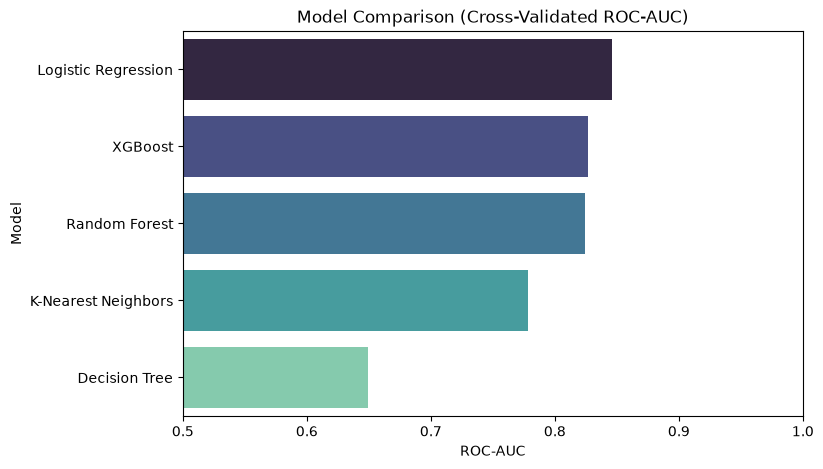

In [14]:
plt.figure(figsize=(8, 5))
sns.barplot(data=cv_results_df, x='ROC-AUC', y='Model', palette='mako')
plt.title('Model Comparison (Cross-Validated ROC-AUC)')
plt.xlim(0.5, 1.0)
plt.show()

XGBoost and Logistic Regression come out ahead on ROC-AUC. XGBoost has more room to improve with tuning, so that's the one worth optimizing further.

In [15]:
xgb_pipe = Pipeline(steps=[
    ('preprocess', preprocessor),
    ('model', XGBClassifier(
        eval_metric='logloss', random_state=42,
        scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum()
    ))
])

param_dist = {
    'model__n_estimators': [100, 200, 300, 400],
    'model__max_depth': [3, 4, 5, 6, 8],
    'model__learning_rate': [0.01, 0.05, 0.1, 0.2],
    'model__subsample': [0.7, 0.8, 0.9, 1.0],
    'model__colsample_bytree': [0.7, 0.8, 0.9, 1.0],
}

search = RandomizedSearchCV(
    xgb_pipe, param_distributions=param_dist, n_iter=20, scoring='roc_auc',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    random_state=42, n_jobs=-1
)
search.fit(X_train, y_train)

print("Best ROC-AUC (CV):", search.best_score_)
print("Best params:", search.best_params_)

best_model = search.best_estimator_

Best ROC-AUC (CV): 0.8499546510968766
Best params: {'model__subsample': 0.8, 'model__n_estimators': 200, 'model__max_depth': 3, 'model__learning_rate': 0.05, 'model__colsample_bytree': 1.0}


### Final evaluation

Tuned XGBoost — Test Set Performance
              precision    recall  f1-score   support

           0       0.91      0.70      0.79      1033
           1       0.49      0.80      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407

ROC-AUC: 0.8375079592692485


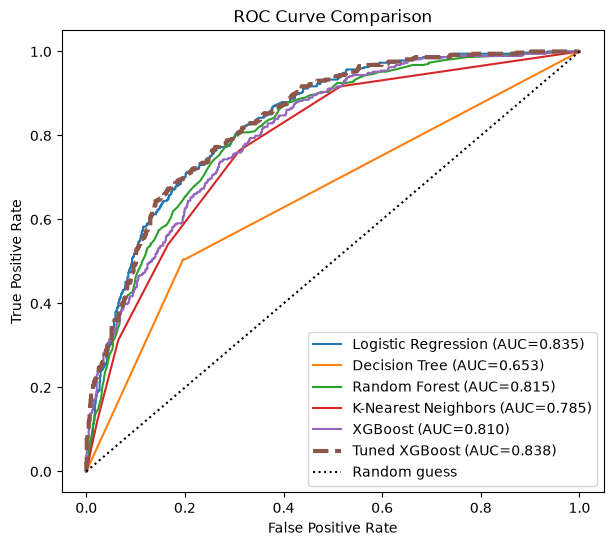

In [16]:
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print("Tuned XGBoost — Test Set Performance")
print(classification_report(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_proba))

plt.figure(figsize=(7, 6))
for name, model in candidate_models.items():
    pipe = Pipeline(steps=[('preprocess', preprocessor), ('model', model)])
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, proba):.3f})")

fpr, tpr, _ = roc_curve(y_test, y_proba)
plt.plot(fpr, tpr, linewidth=3, linestyle='--', label=f"Tuned XGBoost (AUC={roc_auc_score(y_test, y_proba):.3f})")
plt.plot([0, 1], [0, 1], 'k:', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.show()

### Threshold tuning (Precision-Recall) + F2 score

Default `predict()` uses a 0.5 cutoff, which isn't necessarily optimal when the churn class matters more
than the non-churn class. Here we scan thresholds on the Precision-Recall curve, pick the one that
maximizes **F2** (recall weighted 2x more than precision — catching churners matters more than a few
false alarms), and re-report metrics at that threshold.

Best threshold by F2: 0.297
  Precision: 0.432 | Recall: 0.917 | F2: 0.749


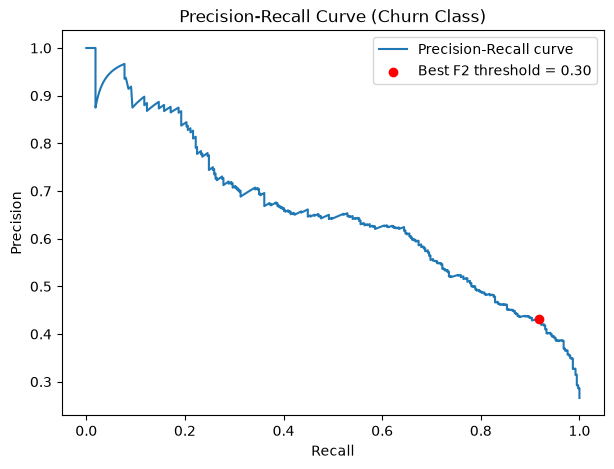


--- Default threshold (0.5) ---
              precision    recall  f1-score   support

           0       0.91      0.70      0.79      1033
           1       0.49      0.80      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407

F1: 0.608 | F2: 0.709

--- Tuned threshold (0.297) ---
              precision    recall  f1-score   support

           0       0.95      0.56      0.71      1033
           1       0.43      0.92      0.59       374

    accuracy                           0.66      1407
   macro avg       0.69      0.74      0.65      1407
weighted avg       0.81      0.66      0.68      1407

F1: 0.587 | F2: 0.749


In [24]:
from sklearn.metrics import precision_recall_curve, fbeta_score, f1_score

precisions, recalls, thresholds = precision_recall_curve(y_test, y_proba)

# F2 score at every threshold (skip last point, precision/recall have len = thresholds+1)
f2_scores = (5 * precisions * recalls) / (4 * precisions + recalls + 1e-12)
best_idx = np.argmax(f2_scores[:-1])
best_threshold = thresholds[best_idx]

print(f"Best threshold by F2: {best_threshold:.3f}")
print(f"  Precision: {precisions[best_idx]:.3f} | Recall: {recalls[best_idx]:.3f} | F2: {f2_scores[best_idx]:.3f}")

plt.figure(figsize=(7, 5))
plt.plot(recalls, precisions, label='Precision-Recall curve')
plt.scatter(recalls[best_idx], precisions[best_idx], color='red', zorder=5,
            label=f'Best F2 threshold = {best_threshold:.2f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve (Churn Class)')
plt.legend()
plt.show()

# Re-classify test set at the tuned threshold and compare to default 0.5
y_pred_tuned = (y_proba >= best_threshold).astype(int)

print("\n--- Default threshold (0.5) ---")
print(classification_report(y_test, y_pred))
print(f"F1: {f1_score(y_test, y_pred):.3f} | F2: {fbeta_score(y_test, y_pred, beta=2.0):.3f}")

print(f"\n--- Tuned threshold ({best_threshold:.3f}) ---")
print(classification_report(y_test, y_pred_tuned))
print(f"F1: {f1_score(y_test, y_pred_tuned):.3f} | F2: {fbeta_score(y_test, y_pred_tuned, beta=2.0):.3f}")


### Feature importance and explainability
Feature importance shows *which* features matter; SHAP shows *how* — e.g. whether short tenure pushes risk up or down, and by how much for a given customer.

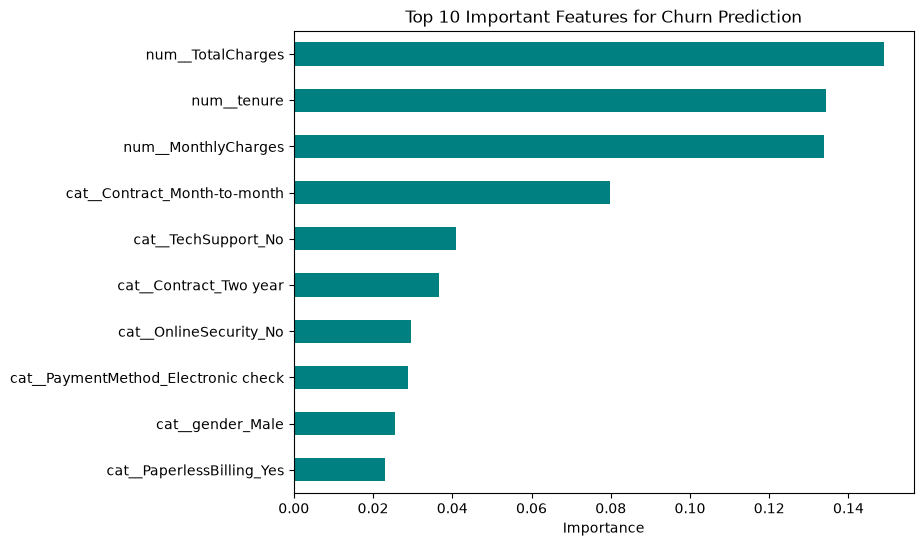

In [25]:
rf_for_importance = RandomForestClassifier(class_weight='balanced', random_state=42)
rf_pipe = Pipeline(steps=[('preprocess', preprocessor), ('model', rf_for_importance)])
rf_pipe.fit(X_train, y_train)

feature_names_rf = rf_pipe.named_steps['preprocess'].get_feature_names_out()
importances = pd.Series(rf_pipe.named_steps['model'].feature_importances_, index=feature_names_rf)
importances.nlargest(10).plot(kind='barh', figsize=(8,6), color='teal')
plt.title('Top 10 Important Features for Churn Prediction')
plt.xlabel('Importance')
plt.gca().invert_yaxis()
plt.show()

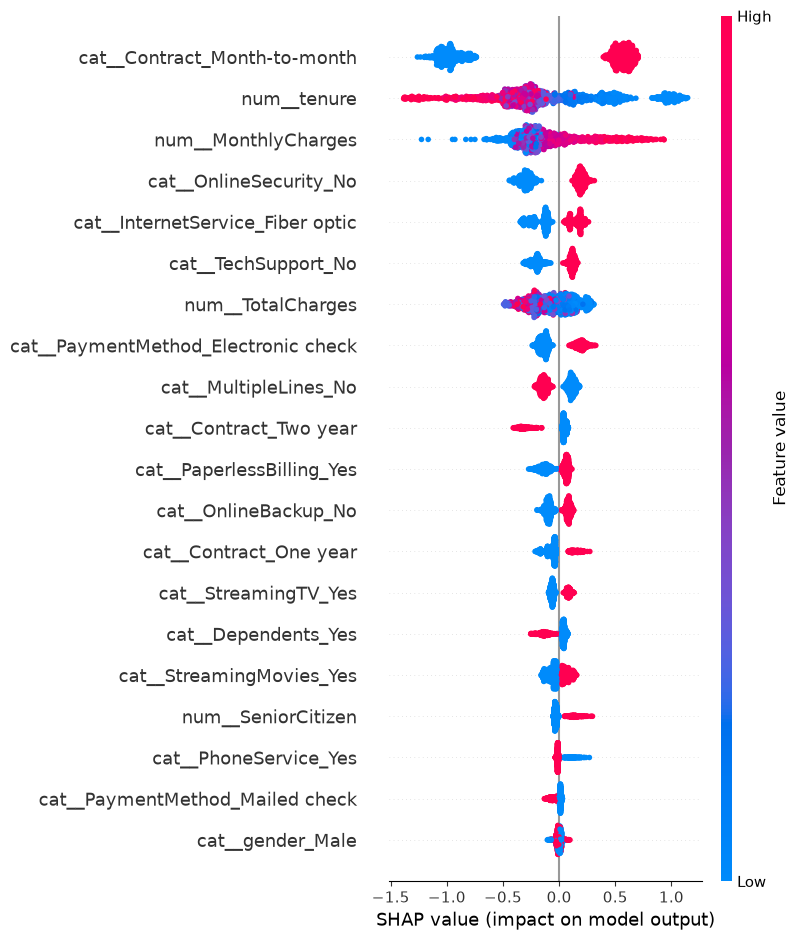

In [26]:
X_test_transformed = best_model.named_steps['preprocess'].transform(X_test)
feature_names = best_model.named_steps['preprocess'].get_feature_names_out()
xgb_model = best_model.named_steps['model']

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test_transformed)

shap.summary_plot(shap_values, X_test_transformed, feature_names=feature_names, show=True)

### Turning the model into an action list
Ranking test customers by churn risk × monthly value, so a retention team could prioritize outreach.

In [27]:
risk_table = X_test.copy()
risk_table['Actual_Churn'] = y_test.values
risk_table['Churn_Probability'] = y_proba
risk_table['Estimated_Monthly_Value'] = risk_table['MonthlyCharges']
risk_table['Priority_Score'] = risk_table['Churn_Probability'] * risk_table['Estimated_Monthly_Value']

top_priority = risk_table.sort_values(by='Priority_Score', ascending=False).head(15)
top_priority[['tenure', 'Contract', 'MonthlyCharges', 'Churn_Probability', 'Priority_Score', 'Actual_Churn']]

,tenure,Contract,MonthlyCharges,Churn_Probability,Priority_Score,Actual_Churn
3949,6,Month-to-month,105.30,0.932357,98.177237,1
3080,3,Month-to-month,105.35,0.929738,97.947890,1
2792,3,Month-to-month,100.95,0.946948,95.594400,1
2241,1,Month-to-month,102.45,0.926773,94.947913,1
2626,7,Month-to-month,99.25,0.949597,94.247502,1
2443,14,Month-to-month,104.85,0.898033,94.158712,1
2289,12,Month-to-month,106.70,0.871189,92.955885,1
6828,11,Month-to-month,100.75,0.921045,92.795332,1
3374,1,Month-to-month,95.10,0.968952,92.147301,1
3721,3,Month-to-month,96.60,0.948799,91.654014,1


In [28]:
joblib.dump(best_model, 'churn_model_pipeline.pkl')
print("Saved tuned pipeline to churn_model_pipeline.pkl")
print(f"\nFinal model: Tuned XGBoost | Test ROC-AUC: {roc_auc_score(y_test, y_proba):.3f} | "
      f"Test F1 (churn class): {classification_report(y_test, y_pred, output_dict=True)['1']['f1-score']:.3f}")

Saved tuned pipeline to churn_model_pipeline.pkl

Final model: Tuned XGBoost | Test ROC-AUC: 0.838 | Test F1 (churn class): 0.608
